# Task 3: Tourist Attractions Data Extraction Using OpenStreetMap

**Selected city:** Mysuru, Karnataka, India

## Objective
Retrieve tourist attractions in Mysuru using the OpenStreetMap Overpass API, clean and organize the results, and save a CSV file containing:

1. Attraction Name
2. Attraction Type
3. Latitude
4. Longitude
5. City/Location

This notebook uses Nominatim only to identify the selected city's OpenStreetMap administrative boundary. The actual attraction records are retrieved from the **Overpass API**.

**Responsible-use notes**
- The notebook sends a small number of requests and identifies itself with a descriptive User-Agent.
- It includes a pause before requests and retries temporary server/rate-limit errors with backoff.
- Do not run the notebook repeatedly in quick succession. Public OSM services are community resources and may be busy.
- The notebook does not attempt to bypass access restrictions or rate limits.

## 1. Install and import libraries

Run this cell first. `requests` sends API requests and `pandas` cleans and exports the data.

In [1]:
!pip -q install requests pandas

import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

print("Libraries are ready.")
print("Pandas version:", pd.__version__)

Libraries are ready.
Pandas version: 2.2.3


## 2. Select the city and configure the APIs

You can change `CITY`, `STATE`, and `COUNTRY` if you want to use another city.

In [2]:
CITY = "Mysuru"
STATE = "Karnataka"
COUNTRY = "India"

LOCATION = f"{CITY}, {STATE}, {COUNTRY}"

NOMINATIM_URL = "https://nominatim.openstreetmap.org/search"
OVERPASS_URL = "https://overpass-api.de/api/interpreter"

# Identify the notebook clearly when accessing public OSM services.
HEADERS = {
    "User-Agent": "TouristAttractionsStudentProject/1.0 (educational data extraction)"
}

print("Selected location:", LOCATION)

Selected location: Mysuru, Karnataka, India


## 3. Find the city's administrative boundary

Nominatim is used to resolve the city name to an OpenStreetMap boundary object. We then use that boundary's OSM ID to form an Overpass area query.

The code prefers a city/municipality administrative boundary. If the search result is not a suitable administrative boundary, it stops and asks you to inspect the result rather than silently querying a larger area.

In [5]:
geo_params = {
    "q": LOCATION,
    "format": "jsonv2",
    "limit": 10,
    "addressdetails": 1,
    "polygon_geojson": 0
}

geo_response = requests.get(
    NOMINATIM_URL,
    params=geo_params,
    headers=HEADERS,
    timeout=30
)
geo_response.raise_for_status()
geo_results = geo_response.json()

if not geo_results:
    raise ValueError(
        f"No OpenStreetMap boundary search result was found for {LOCATION}. "
        "Check the city/state spelling and try again."
    )

# Show candidates so the selected administrative boundary is transparent.
candidate_rows = []
for item in geo_results:
    candidate_rows.append({
        "display_name": item.get("display_name"),
        "osm_type": item.get("osm_type"),
        "osm_id": item.get("osm_id"),
        "class": item.get("category") or item.get("class"),
        "type": item.get("type"),
        "addresstype": item.get("addresstype")
    })

display(pd.DataFrame(candidate_rows))

# Prefer an administrative or local_authority relation whose name matches the selected city.
city_names = {CITY.casefold(), "mysore"}
admin_candidates = [
    item for item in geo_results
    if (item.get("category") == "boundary" or item.get("class") == "boundary")
    and item.get("type") in ("administrative", "local_authority")
    and item.get("osm_type") == "relation"
]

exact_candidates = [
    item for item in admin_candidates
    if item.get("name", "").casefold() in city_names
]

if exact_candidates:
    boundary = exact_candidates[0]
elif admin_candidates:
    # Use only when Nominatim has returned an administrative relation
    # for the full requested location; display the choice below.
    boundary = admin_candidates[0]
else:
    raise ValueError(
        "Nominatim did not return an administrative boundary relation. "
        "Inspect the candidates above; do not use a district or state boundary by mistake."
    )

print("\nSelected boundary:")
print("Name:", boundary.get("name"))
print("OSM type:", boundary.get("osm_type"))
print("OSM ID:", boundary.get("osm_id"))
print("Display name:", boundary.get("display_name"))

,display_name,osm_type,osm_id,class,type,addresstype
0,"Mysuru, Mysuru taluk, Mysuru District, Karnata...",relation,19125269,boundary,local_authority,local_authority
1,"Mysuru, Mysuru taluk, Mysuru District, Karnata...",node,2068274800,place,city,city



Selected boundary:
Name: Mysuru
OSM type: relation
OSM ID: 19125269
Display name: Mysuru, Mysuru taluk, Mysuru District, Karnataka, 570001, India


## 4. Convert the boundary relation to an Overpass area ID

For an OpenStreetMap relation, the corresponding Overpass area ID is calculated by adding `3600000000` to its relation ID.

In [6]:
if boundary["osm_type"] != "relation":
    raise ValueError("This notebook expects a city administrative relation.")

osm_relation_id = int(boundary["osm_id"])
overpass_area_id = 3600000000 + osm_relation_id

print("OSM relation ID:", osm_relation_id)
print("Overpass area ID:", overpass_area_id)

OSM relation ID: 19125269
Overpass area ID: 3619125269


## 5. Query tourist attractions using the Overpass API

The query searches for:
- Tourist attractions
- Museums, galleries, zoos, aquariums and theme parks
- Historic places and monuments
- Parks and gardens

It retrieves nodes, ways and relations (`nwr`). The `center` output provides approximate coordinates for ways and relations, which usually do not have a single `lat` and `lon` field.

In [7]:
overpass_query = f'''
[out:json][timeout:90];
area({overpass_area_id})->.cityArea;
(
  nwr["tourism"~"^(attraction|museum|gallery|zoo|aquarium|theme_park)$"](area.cityArea);
  nwr["historic"](area.cityArea);
  nwr["leisure"~"^(park|garden)$"](area.cityArea);
);
out center tags;
'''

# A short pause before the public API request.
time.sleep(1)

overpass_response = requests.post(
    OVERPASS_URL,
    data={"data": overpass_query},
    headers=HEADERS,
    timeout=120
)

print("Overpass API status:", overpass_response.status_code)
overpass_response.raise_for_status()

overpass_data = overpass_response.json()
elements = overpass_data.get("elements", [])

print("Total OSM elements retrieved:", len(elements))

if not elements:
    raise ValueError(
        "The Overpass query returned no elements for this boundary. "
        "Check the selected boundary and try again later if the API is busy."
    )

Overpass API status: 200
Total OSM elements retrieved: 226


## 6. Convert the API response into structured records

The attraction type is derived from the OpenStreetMap tags. If an object has more than one relevant tag, the code applies a consistent priority: tourism category, historic category, then park/garden.

In [8]:
def get_attraction_type(tags):
    tourism = tags.get("tourism")
    historic = tags.get("historic")
    leisure = tags.get("leisure")

    tourism_types = {
        "attraction": "Tourist Attraction",
        "museum": "Museum",
        "gallery": "Art Gallery",
        "zoo": "Zoo",
        "aquarium": "Aquarium",
        "theme_park": "Theme Park"
    }

    if tourism in tourism_types:
        return tourism_types[tourism]

    if historic:
        # Keep the specific historic tag value where possible.
        return historic.replace("_", " ").title()

    if leisure == "park":
        return "Park"

    if leisure == "garden":
        return "Garden"

    return "Other Tourist Attraction"


records = []

for element in elements:
    tags = element.get("tags", {})
    name = tags.get("name")

    # Latitude/longitude are direct fields for nodes and "center" for ways/relations.
    if "lat" in element and "lon" in element:
        latitude = element.get("lat")
        longitude = element.get("lon")
    else:
        center = element.get("center", {})
        latitude = center.get("lat")
        longitude = center.get("lon")

    records.append({
        "Attraction Name": name,
        "Attraction Type": get_attraction_type(tags),
        "Latitude": latitude,
        "Longitude": longitude,
        "City/Location": LOCATION,
        # Internal identifiers are retained temporarily for reliable OSM-object deduplication.
        "_OSM Type": element.get("type"),
        "_OSM ID": element.get("id")
    })

raw_df = pd.DataFrame(records)

print("Records converted from API response:", len(raw_df))
display(raw_df.head(10))

Records converted from API response: 226


,Attraction Name,Attraction Type,Latitude,Longitude,City/Location,_OSM Type,_OSM ID
0,Kaveri Kala Kuteera,Museum,12.291861,76.632179,"Mysuru, Karnataka, India",node,542404091
1,Narasimharaja Wodeyar,Monument,12.308279,76.655826,"Mysuru, Karnataka, India",node,1153369645
2,Krishnaraja Wodeyar,Monument,12.308784,76.653066,"Mysuru, Karnataka, India",node,3224357583
3,Sand museum,Museum,12.295029,76.682019,"Mysuru, Karnataka, India",node,3276157874
4,Melody World Wax Museum,Museum,12.302396,76.677720,"Mysuru, Karnataka, India",node,3276157977
5,Indira Gandhi Rashtriya Manav Sangrahalaya,Museum,12.314503,76.657605,"Mysuru, Karnataka, India",node,3300627908
6,KPC Glass House,Tourist Attraction,12.310159,76.648064,"Mysuru, Karnataka, India",node,3390746047
7,Tengina Topu,Park,12.301779,76.632925,"Mysuru, Karnataka, India",node,4012599895
8,Birds Watch Tower,Tourist Attraction,12.303731,76.676206,"Mysuru, Karnataka, India",node,4585165992
9,Funway,Tourist Attraction,12.295285,76.683099,"Mysuru, Karnataka, India",node,4585237547


## 7. Clean and organize the dataset

Cleaning steps:
- Remove attractions without a name because the required Attraction Name field must be present.
- Remove records without valid coordinates.
- Convert latitude and longitude to numeric values.
- Check that coordinates fall within valid geographic ranges.
- Remove duplicate OpenStreetMap objects using their OSM type and ID.
- Remove exact duplicate attraction rows.

In [9]:
clean_df = raw_df.copy()

# Remove records without a usable name.
clean_df["Attraction Name"] = clean_df["Attraction Name"].astype("string").str.strip()
clean_df = clean_df[
    clean_df["Attraction Name"].notna()
    & clean_df["Attraction Name"].ne("")
].copy()

# Convert coordinates to numeric values.
clean_df["Latitude"] = pd.to_numeric(clean_df["Latitude"], errors="coerce")
clean_df["Longitude"] = pd.to_numeric(clean_df["Longitude"], errors="coerce")

# Remove missing or geographically invalid coordinates.
clean_df = clean_df.dropna(subset=["Latitude", "Longitude"]).copy()
clean_df = clean_df[
    clean_df["Latitude"].between(-90, 90)
    & clean_df["Longitude"].between(-180, 180)
].copy()

# Remove repeated OSM objects.
clean_df = clean_df.drop_duplicates(subset=["_OSM Type", "_OSM ID"])

# Remove exact duplicate output records.
required_columns = [
    "Attraction Name",
    "Attraction Type",
    "Latitude",
    "Longitude",
    "City/Location"
]
clean_df = clean_df.drop_duplicates(subset=required_columns)

# Keep the five fields requested in the assignment.
final_df = clean_df[required_columns].copy()

# Sort for readability.
final_df = final_df.sort_values(
    by=["Attraction Type", "Attraction Name"],
    kind="stable"
).reset_index(drop=True)

print("Records before cleaning:", len(raw_df))
print("Records after cleaning:", len(final_df))
print("\nMissing values in final dataset:")
display(final_df.isna().sum().to_frame("Missing Values"))

display(final_df.head(15))

Records before cleaning: 226
Records after cleaning: 88

Missing values in final dataset:


,Missing Values
Attraction Name,0
Attraction Type,0
Latitude,0
Longitude,0
City/Location,0


,Attraction Name,Attraction Type,Latitude,Longitude,City/Location
0,Lokaranjan Aquarium,Aquarium,12.304807,76.663947,"Mysuru, Karnataka, India"
1,Jaganmohan Palace and Art Gallery,Art Gallery,12.306791,76.649685,"Mysuru, Karnataka, India"
2,Mysore Palace,Castle,12.305254,76.656074,"Mysuru, Karnataka, India"
3,Main Gate,City Gate,12.336745,76.618576,"Mysuru, Karnataka, India"
4,Kishkindha Moolika Bonsai Garden,Garden,12.284281,76.657967,"Mysuru, Karnataka, India"
5,Krishnaraja Wodeyar,Monument,12.308784,76.653066,"Mysuru, Karnataka, India"
6,Narasimharaja Wodeyar,Monument,12.308279,76.655826,"Mysuru, Karnataka, India"
7,House of R. K. Narayan,Museum,12.327932,76.640705,"Mysuru, Karnataka, India"
8,Indira Gandhi Rashtriya Manav Sangrahalaya,Museum,12.314503,76.657605,"Mysuru, Karnataka, India"
9,Indira Gandhi Rashtriya Manav Sangrahalaya,Museum,12.314496,76.657520,"Mysuru, Karnataka, India"


## 8. Summarize the extracted attraction types

This is a quick check of how many records were collected under each attraction type.

In [10]:
type_summary = (
    final_df["Attraction Type"]
    .value_counts()
    .rename_axis("Attraction Type")
    .reset_index(name="Number of Attractions")
)

display(type_summary)

print("Total cleaned attractions:", len(final_df))

,Attraction Type,Number of Attractions
0,Park,59
1,Museum,11
2,Tourist Attraction,9
3,Monument,2
4,Castle,1
5,Aquarium,1
6,Art Gallery,1
7,City Gate,1
8,Garden,1
9,Yes,1


Total cleaned attractions: 88


## 9. Validate the required fields

The assignment asks for five fields. This cell checks that all five columns are present and that no missing values remain in the final output.

In [11]:
expected_columns = [
    "Attraction Name",
    "Attraction Type",
    "Latitude",
    "Longitude",
    "City/Location"
]

assert list(final_df.columns) == expected_columns, "Required columns do not match."
assert len(final_df) > 0, "The cleaned dataset is empty."
assert final_df[expected_columns].notna().all().all(), "Missing values remain."

print("Validation successful.")
print("Required columns:", list(final_df.columns))
print("Final number of records:", len(final_df))

Validation successful.
Required columns: ['Attraction Name', 'Attraction Type', 'Latitude', 'Longitude', 'City/Location']
Final number of records: 88


## 10. Save the final dataset as CSV

The CSV file is saved in the current notebook working directory. In Google Colab, it will normally be saved under `/content/`.

In [12]:
output_file = "mysuru_tourist_attractions.csv"

final_df.to_csv(output_file, index=False, encoding="utf-8-sig")

print("CSV file saved successfully:", output_file)
print("Number of rows:", len(final_df))
print("Number of columns:", len(final_df.columns))

CSV file saved successfully: mysuru_tourist_attractions.csv
Number of rows: 88
Number of columns: 5


## 11. View the scraped dataset

Display the first few rows of the final scraped dataset and confirm its structure.

In [13]:
print("First 5 rows of the scraped dataset:")
display(final_df.head())

print("\nDataset shape:", final_df.shape)
print("\nColumn names:")
print(final_df.columns.tolist())

First 5 rows of the scraped dataset:


,Attraction Name,Attraction Type,Latitude,Longitude,City/Location
0,Lokaranjan Aquarium,Aquarium,12.304807,76.663947,"Mysuru, Karnataka, India"
1,Jaganmohan Palace and Art Gallery,Art Gallery,12.306791,76.649685,"Mysuru, Karnataka, India"
2,Mysore Palace,Castle,12.305254,76.656074,"Mysuru, Karnataka, India"
3,Main Gate,City Gate,12.336745,76.618576,"Mysuru, Karnataka, India"
4,Kishkindha Moolika Bonsai Garden,Garden,12.284281,76.657967,"Mysuru, Karnataka, India"



Dataset shape: (88, 5)

Column names:
['Attraction Name', 'Attraction Type', 'Latitude', 'Longitude', 'City/Location']


## 12. Missing-value analysis

Check whether any of the five required fields contain missing values.

Missing values in each column:


,Missing Value Count
Attraction Name,0
Attraction Type,0
Latitude,0
Longitude,0
City/Location,0



Total missing values: 0


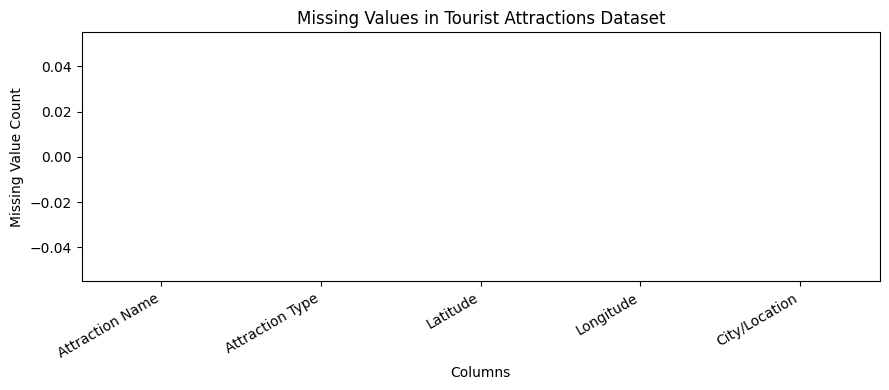

In [14]:
print("Missing values in each column:")
missing_values = final_df.isnull().sum()
display(missing_values.to_frame(name="Missing Value Count"))

print("\nTotal missing values:", int(missing_values.sum()))

plt.figure(figsize=(9, 4))
missing_values.plot(kind="bar")
plt.title("Missing Values in Tourist Attractions Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Value Count")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 13. Attraction type and distribution

Count the number of attractions in each category and visualize the distribution.

Attraction Type Counts:
Attraction Type
Park                  59
Museum                11
Tourist Attraction     9
Monument               2
Castle                 1
Aquarium               1
Art Gallery            1
City Gate              1
Garden                 1
Yes                    1
Zoo                    1
Name: count, dtype: int64


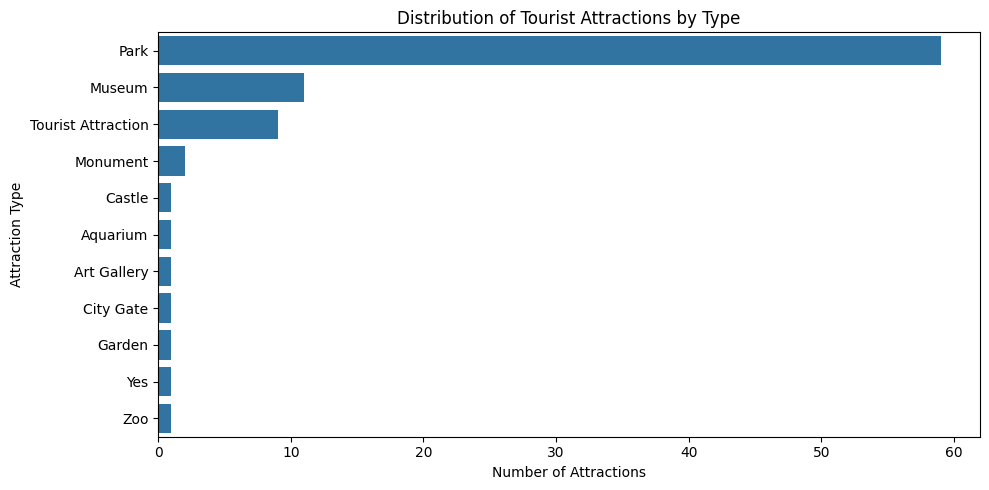

In [15]:
type_counts = final_df["Attraction Type"].value_counts()

print("Attraction Type Counts:")
print(type_counts)

plt.figure(figsize=(10, 5))
sns.barplot(x=type_counts.values, y=type_counts.index)
plt.title("Distribution of Tourist Attractions by Type")
plt.xlabel("Number of Attractions")
plt.ylabel("Attraction Type")
plt.tight_layout()
plt.show()

## 14. Final dataset summary

Display the total number of cleaned attractions, unique attraction types, unique attraction names, and the count of records by attraction type.

In [16]:
print("Total Cleaned Attractions:", len(final_df))
print("Unique Attraction Types:", final_df["Attraction Type"].nunique())
print("Unique Attraction Names:", final_df["Attraction Name"].nunique())

print("\nAttraction Type Counts:")
print(type_counts)

Total Cleaned Attractions: 88
Unique Attraction Types: 11
Unique Attraction Names: 84

Attraction Type Counts:
Attraction Type
Park                  59
Museum                11
Tourist Attraction     9
Monument               2
Castle                 1
Aquarium               1
Art Gallery            1
City Gate              1
Garden                 1
Yes                    1
Zoo                    1
Name: count, dtype: int64
